# 01 · EDA and metric analysis

Point 1 of `PLAN.md` (owner: Ivan). This notebook keeps only the facts that change modelling decisions, and each
section ends with a **→ decision**.

| File | What it is | Role |
|---|---|---|
| `uk_geo_dataset.csv` | ~1M Ukr-Synth sentences with silver location spans | train (`is_valid==0`) and early stopping (`is_valid==1`) |
| `labeling_sample.csv` | 26 test-like texts with gold locations | CV |
| `test.csv` | 477 Telegram posts, no labels | Kaggle submission |

## Key findings
1. **Strong domain shift.**
   - Train is short, clean sentences: median 16 words, no emoji, no line breaks.
   - Test is Telegram posts: median 46 words, 63% with emoji, 85% with line breaks, 7% Russian.
2. **The test-like gold follows its own convention.**
   - Repeated channel signatures (`Життя🫶Оболонь`, `Хуйовий Київ | Надіслати новину`) are **never** labeled,
     and 35% of test posts contain one.
   - Countries are probably not labeled either. The only clean case, `мир в Україні`, is not gold. This is weak
     evidence, so we check it on LB.

   In train, by contrast, the most frequent locations are `України`, `США` and `Росії`.
3. **The location types differ.** The CV gold has streets, districts, malls, addresses and inflected towns of the Kyiv
   region. 28% of its location words are out of a 50k train vocabulary.
4. **Silver labels are mostly clean.** 4% of train spans are off token boundaries, almost all of them hyphenated names
   split in two. With our tokenizer, the gold round trip scores 0.97 on train and 1.00 on CV.
5. **The metric is all or nothing per normalized string.** A boundary error costs an FP *and* an FN. A prediction that
   normalizes to an empty string (`В`, `28`) is also an FP.
6. **A no-ML gazetteer of train locations already scores 0.427 on CV.** Any RNN must beat it.
   Its errors show where the points are: precision 0.33 because of countries, signatures and common words, and the
   multi-word streets that it misses.

## 0. Setup
The notebook runs on Colab and locally.
- **On Colab:** upload `secrets.env` (`KAGGLE_USERNAME`, `KAGGLE_KEY`, `WANDB_API_KEY`) to `/content/` first. The cell
  below loads the keys and downloads the data with the Kaggle CLI. It prints only the names of the keys it found,
  never their values.
- **Locally:** the data is read from `data/raw/`.

In [1]:
import os
import shutil
import subprocess
from pathlib import Path

COMPETITION = "kse-ua-location-extraction-2026"
DATA_FILES = ["uk_geo_dataset.csv", "labeling_sample.csv", "test.csv"]
IN_COLAB = Path("/content").exists()


def load_secrets(path: Path = Path("/content/secrets.env")) -> None:
    assert path.exists(), f"Upload secrets.env to {path.parent} first"
    for line in path.read_text().splitlines():
        if "=" in line and not line.lstrip().startswith("#"):
            key, value = line.split("=", 1)
            os.environ[key.strip()] = value.strip()
    print("keys loaded:", [k for k in ("KAGGLE_USERNAME", "KAGGLE_KEY", "WANDB_API_KEY") if os.environ.get(k)])


def download_data(raw: Path) -> None:
    raw.mkdir(parents=True, exist_ok=True)
    for name in DATA_FILES:
        if (raw / name).exists():
            continue
        subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-f", name, "-p", str(raw)], check=True)
        archive = raw / f"{name}.zip"
        if archive.exists():  # large files arrive zipped
            shutil.unpack_archive(archive, raw)
            archive.unlink()


if IN_COLAB:
    RAW = Path("/content/data/raw")
    load_secrets()
    download_data(RAW)
else:
    RAW = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data/raw"
print({name: f"{(RAW / name).stat().st_size / 1e6:.0f} MB" for name in DATA_FILES})

{'uk_geo_dataset.csv': '211 MB', 'labeling_sample.csv': '0 MB', 'test.csv': '0 MB'}


### 0.1 Shared code: tokenizer, span ↔ BIO, competition metric
Every training notebook uses the same code. Each token keeps its character offsets, so predicted tags can be turned
back into **exact substrings** of the text, which is what the metric compares. Punctuation becomes its own token
(`Київ,` → `Київ` `,`), while inner hyphens and apostrophes stay inside the word (`Івано-Франківськ`,
`Слов'янськ`).

In [2]:
import ast
import re
import string
from collections import Counter
from dataclasses import dataclass
from typing import List, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

TOKEN_RE = re.compile(r"\w+(?:[-'’ʼ`]\w+)*|[^\w\s]")


@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int  # exclusive


def word_tokenize(text: str) -> list[Token]:
    return [Token(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def parse_markers(value) -> list[tuple[int, int]]:
    """`loc_markers` as stored in the CSV ("[(0, 4), (10, 15)]") -> [(start, end), ...], end exclusive."""
    if not isinstance(value, str):
        return []
    return [(int(a), int(b)) for a, b in ast.literal_eval(value.strip() or "[]")]


def spans_to_bio(tokens: Sequence[Token], spans) -> list[str]:
    """Every token that overlaps a span is labelled: the first one B-LOC, the rest I-LOC."""
    labels = ["O"] * len(tokens)
    for left, right in sorted(spans):
        first = True
        for i, tok in enumerate(tokens):
            if tok.start < right and tok.end > left:
                labels[i] = "B-LOC" if first else "I-LOC"
                first = False
    return labels


def bio_to_spans(tokens: Sequence[Token], tags: Sequence[str]) -> list[tuple[int, int]]:
    """Merge BIO tags into character spans; an I-LOC without an open entity starts a new one."""
    spans, current = [], None
    for tok, tag in zip(tokens, tags):
        if tag == "B-LOC" or (tag == "I-LOC" and current is None):
            if current is not None:
                spans.append(tuple(current))
            current = [tok.start, tok.end]
        elif tag == "I-LOC":
            current[1] = tok.end
        else:
            if current is not None:
                spans.append(tuple(current))
            current = None
    if current is not None:
        spans.append(tuple(current))
    return spans


def spans_to_strings(text: str, spans) -> list[str]:
    """Cut location strings out of the original text (deduplicated, order kept)."""
    return list(dict.fromkeys(s for s in (text[a:b].strip() for a, b in spans) if s))

`hard_processing` and `comp_metric` below are copied **verbatim** from the competition page. Do not "fix" them.

In [3]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p,  = 0.0, 0.0, 0.0, 0.0

    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])

        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)

    if tp + fp == 0:
        if p == 0:
            precision = 1.0
        else:
            precision = 0.0
    else:
        precision = tp/(tp + fp)

    if tp + fn == 0:
        if p == 0:
            recall = 1.0
        else:
            recall = 0.0
    else:
        recall = tp/(tp + fn)

    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

Our complementary metrics (section 7). They count exactly like `comp_metric`, plus:

In [4]:
def precision_recall(y_true, y_pred) -> tuple[float, float]:
    tp = fp = fn = 0
    for t_s, p_s in zip(y_true, y_pred):
        t, p = {hard_processing(s) for s in t_s}, {hard_processing(s) for s in p_s}
        tp, fp, fn = tp + len(t & p), fp + len(p - t), fn + len(t - p)
    precision = tp / (tp + fp) if tp + fp else float(tp + fn == 0)
    recall = tp / (tp + fn) if tp + fn else 1.0
    return precision, recall


def partial_match_f1(y_true, y_pred) -> float:
    """Boundary-tolerant F1: a location counts if it shares a normalized word with one on the other side."""
    words = lambda s: set(hard_processing(s).split())
    hit_p = n_p = hit_t = n_t = 0
    for t_s, p_s in zip(y_true, y_pred):
        t_sets = [words(s) for s in {hard_processing(x) for x in t_s}]
        p_sets = [words(s) for s in {hard_processing(x) for x in p_s}]
        n_p, n_t = n_p + len(p_sets), n_t + len(t_sets)
        hit_p += sum(any(p & t for t in t_sets) for p in p_sets)
        hit_t += sum(any(t & p for p in p_sets) for t in t_sets)
    precision, recall = (hit_p / n_p if n_p else 1.0), (hit_t / n_t if n_t else 1.0)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0


def metric_report(y_true, y_pred) -> dict:
    precision, recall = precision_recall(y_true, y_pred)
    no_loc = [len(p) > 0 for t, p in zip(y_true, y_pred) if not t]
    with_loc = [(t, p) for t, p in zip(y_true, y_pred) if t]
    return {
        "comp_f1": comp_metric(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "partial_f1": partial_match_f1(y_true, y_pred),
        "f1_texts_with_loc": comp_metric([t for t, _ in with_loc], [p for _, p in with_loc]),
        "fp_rate_texts_without_loc": float(np.mean(no_loc)) if no_loc else 0.0,
    }

### 0.2 Load the data

In [5]:
uk = pd.read_csv(RAW / "uk_geo_dataset.csv")
ls = pd.read_csv(RAW / "labeling_sample.csv")
test = pd.read_csv(RAW / "test.csv")
for df in (uk, ls):
    df["spans"] = df.loc_markers.map(parse_markers)

train, es = uk[uk.is_valid == 0], uk[uk.is_valid == 1]
train_s = train.sample(100_000, random_state=0)  # token-level statistics on a 100k sample of train
print(f"train={len(train):,}  es={len(es):,}  labeling_sample={len(ls)}  test={len(test)}")

train=1,000,000  es=10,000  labeling_sample=26  test=477


## 1. Data quality

In [6]:
test_texts = set(test.text)
pd.DataFrame({
    "rows": [len(train), len(es), len(ls), len(test)],
    "missing values": [int(d.text.isna().sum()) for d in (train, es, ls, test)],
    "duplicate texts": [int(d.text.duplicated().sum()) for d in (train, es, ls, test)],
    "texts also in test": [int(d.text.isin(test_texts).sum()) for d in (train, es, ls)] + ["-"],
}, index=["train", "es", "labeling_sample", "test"])

,rows,missing values,duplicate texts,texts also in test
train,1000000,0,2402,0
es,10000,0,0,0
labeling_sample,26,0,0,0
test,477,0,0,-


In [7]:
# labeling_sample stores the gold twice: as strings (`locations`) and as character markers. Do they agree?
ls_strings = ls.locations.map(ast.literal_eval)
ls_from_markers = [[t[a:b] for a, b in s] for t, s in zip(ls.text, ls.spans)]
print("rows where `locations` == strings cut by markers:",
      sum(sorted(a) == sorted(b) for a, b in zip(ls_strings, ls_from_markers)), "of", len(ls))
print("test columns:", list(test.columns), "| test `locations` values:", test.locations.unique()[:3])

rows where `locations` == strings cut by markers: 26 of 26
test columns: ['text_id', 'text', 'locations'] | test `locations` values: <StringArray>
['[]']
Length: 1, dtype: str


- No missing values and no train/test text overlap. The 2,402 duplicate train sentences (0.2%) are harmless.
- `is_valid==1` is only 10k rows (1%) and comes from the same domain as train.
- `labeling_sample` is the only test-like data with gold: 26 texts. Its `locations` strings and character markers agree
  in all rows, and marker ends are exclusive.
- The `locations` column of `test.csv` is always `[]`. It is a placeholder.

**→ decision:** train on `is_valid==0`, early-stop on `is_valid==1` (`es`), and use `labeling_sample` as CV (point 2).

## 2. Domain shift: train vs test-like texts

In [8]:
EMOJI_RE = re.compile(r"[\U0001F300-\U0001FAFF☀-➿⬀-⯿️]")


def is_russian(text: str) -> bool:
    return bool(re.search(r"[ыэъё]", text, re.I))


def profile(df: pd.DataFrame) -> tuple[dict, pd.Series]:
    n_words = df.text.map(lambda t: len(word_tokenize(t)))
    row = {
        "median words": n_words.median(),
        "p95 words": n_words.quantile(0.95),
        "share > 256 words": (n_words > 256).mean(),
        "has emoji": df.text.map(lambda t: bool(EMOJI_RE.search(t))).mean(),
        "has line break": df.text.str.contains("\n").mean(),
        "has Latin word": df.text.str.contains(r"\b[A-Za-z]{3,}\b").mean(),
        "Russian": df.text.map(is_russian).mean(),
    }
    return row, n_words


rows, lengths = {}, {}
for name, df in [("train", train_s), ("es", es), ("labeling_sample", ls), ("test", test)]:
    rows[name], lengths[name] = profile(df)
pd.DataFrame(rows).round(3)

,train,es,labeling_sample,test
median words,16.000,16.000,36.500,46.000
p95 words,33.000,34.000,159.750,196.200
share > 256 words,0.000,0.000,0.000,0.025
has emoji,0.000,0.000,0.692,0.627
has line break,0.000,0.000,0.808,0.851
has Latin word,0.058,0.057,0.154,0.247
Russian,0.001,0.001,0.038,0.071


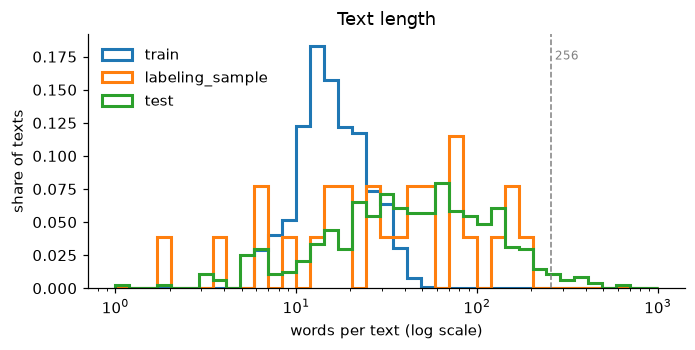

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(0, np.log10(1000), 40)
for name in ("train", "labeling_sample", "test"):  # es has the same profile as train
    n = lengths[name]
    ax.hist(n, bins=bins, weights=np.full(len(n), 1 / len(n)), histtype="step", lw=2, label=name)
ax.axvline(256, color="grey", ls="--", lw=1)
ax.text(270, ax.get_ylim()[1] * 0.9, "256", color="grey", fontsize=8)
ax.set(xscale="log", xlabel="words per text (log scale)", ylabel="share of texts", title="Text length")
ax.legend(frameon=False)
plt.show()

- Test posts are about 3× longer than train sentences, and 2.5% of them have more than 256 words.
- Emoji, line breaks and Latin words (links, `Instagram`, `YouTube`) never appear in train. To the model they are just
  `<unk>` tokens or punctuation.
- Russian is 7% of test posts and almost absent from train.
- `labeling_sample` matches the test profile, which supports using it as CV.

**→ decisions:**
- At inference, never truncate test posts. An RNN can run on any length, so `max_len` applies only to training batches.
- Bidirectional models: list-style posts (`Фастів - 11`) need the right context.
- Emoji and punctuation must never start, end or sit inside a predicted location (point 7).

## 3. Labels: imbalance and what locations look like

In [10]:
def label_stats(df: pd.DataFrame) -> dict:
    tags = [tag for text, spans in zip(df.text, df.spans) for tag in spans_to_bio(word_tokenize(text), spans)]
    n_loc = df.spans.map(len)
    return {
        "texts with ≥1 location": (n_loc > 0).mean(),
        "locations per text": n_loc.mean(),
        "share of LOC tokens": np.mean([t != "O" for t in tags]),
    }


def location_strings(df: pd.DataFrame) -> list[str]:
    return [text[a:b] for text, spans in zip(df.text, df.spans) for a, b in spans]


train_locs, gold_locs = location_strings(train_s), location_strings(ls)
words_per_loc = lambda locs: pd.Series([len(word_tokenize(x)) for x in locs]).clip(upper=5).value_counts(normalize=True)
display(pd.DataFrame({"train": label_stats(train_s), "labeling_sample": label_stats(ls)}).round(3))
pd.DataFrame({"train": words_per_loc(train_locs), "labeling_sample": words_per_loc(gold_locs)}) \
    .sort_index().fillna(0).round(3).rename_axis("tokens per location (5 = 5+)").T

,train,labeling_sample
texts with ≥1 location,0.232,0.615
locations per text,0.344,1.231
share of LOC tokens,0.023,0.034


tokens per location (5 = 5+),1,2,3,4,5
train,0.841,0.126,0.019,0.008,0.005
labeling_sample,0.719,0.219,0.000,0.000,0.062


In [11]:
print("Top-20 train locations:", ", ".join(f"{s} ({c})" for s, c in Counter(train_locs).most_common(20)))
print("\nAll labeling_sample gold locations:", gold_locs)

Top-20 train locations: України (2429), Україні (1688), США (846), Росії (769), Україна (743), Києві (658), Україну (387), Києва (386), Криму (355), Росія (348), РФ (345), Донбасі (308), Київ (267), Польщі (267), Львові (245), Франції (222), Європи (216), Львова (212), Івано (193), Росією (191)

All labeling_sample gold locations: ['Проспект Бандери', 'Київщині', 'Чорнобиль', 'Київ', 'Тетерів', 'Фастів', 'Біла Церква', 'Миронівка', 'Бориспіль', 'Яготин', 'Баришівка', 'проспекті Івасюка', 'Києва', 'Хелма', 'Києву', 'ТЦ Аркадія', 'Фастовском', 'Бучанском', 'Троєщині', 'Шевченківському районі', 'Героїв Дніпра', "вул. Солом'янська, 28", 'Києвом', 'Васильковом', 'Києва', 'Броварах', 'Київщині', 'Києві', 'Подолі', 'Пскові', 'вулиці Здолбунівській', 'вул. Здолбунівська, 1']


- **Imbalance.**
  - Only 2.3% of train tokens are LOC, and 77% of train sentences have no location.
  - On CV, 62% of texts have a location.

  The model sees mostly `O`, so recall is the risk. This suggests class weights or threshold tuning (point 7).
- **Train locations are countries and big cities.** 84% of them are single words.
- **Test-like gold is local and longer.** It has streets (`проспекті Івасюка`, `вул. Солом'янська, 28`), districts
  (`Шевченківському районі`), malls (`ТЦ Аркадія`), towns of the Kyiv region in inflected forms (`Васильковом`,
  `Київщині`) and Russian forms (`Фастовском`, `Пскові`). 28% of gold locations have 2 or more words, vs 16% in train.
- The street-type word (`вул.`, `проспекті`) and the house number are part of the gold string.

**→ decisions:** output the surface form exactly as written (never lemmatize). Multi-word spans matter, so BIO decoding
and entity merging (point 7) are worth tuning.

### 3.1 What the CV gold does *not* label
The gazetteer errors in section 7 led here. We check two conventions of the test-like annotation:
1. Are countries labeled?
2. Are the channel signatures that end many posts labeled?

In [12]:
COUNTRY_RE = re.compile(r"\b(?:Україн|Украин|Росі|Росси|Польщ)\w*|\b(?:РФ|США)\b")
pd.DataFrame([{"mention": m.group(), "in gold": m.group() in gold,
               "context": text[max(0, m.start() - 45):m.end() + 20].replace("\n", " ⏎ ")}
              for text, gold in zip(ls.text, ls_strings) for m in COUNTRY_RE.finditer(text)])

,mention,in gold,context
0,України,False,ими. Не забувайте допомагати Збройним Силам України і таким чином набли
1,Україні,False,Силам України і таким чином наближати мир в Україні після нашої Перемог
2,України,False,я Рустема Умерова на посаду міністра оборони України. ⏎ ⏎ Більше кадрових
3,України,False,"‼️Я вирішив провести заміну міністра оборони України, – Зеленський ⏎ ⏎ Очол"


In [13]:
line_counts = Counter(line.strip() for text in test.text for line in set(text.splitlines()) if line.strip())
signatures = {line for line, count in line_counts.items() if count >= 5}
has_signature = lambda text: any(line.strip() in signatures for line in text.splitlines())
gold_in_signature = sum(text[a:b] in line for text, spans in zip(ls.text, ls.spans) for a, b in spans
                        for line in text.splitlines() if line.strip() in signatures)
print(f"{len(signatures)} lines repeat in ≥5 test posts; {test.text.map(has_signature).mean():.0%} of test posts "
      f"and {ls.text.map(has_signature).mean():.0%} of CV texts contain one; CV gold spans inside them: {gold_in_signature}")
pd.Series({line: line_counts[line] for line in signatures}, name="test posts").sort_values(ascending=False).to_frame()

14 lines repeat in ≥5 test posts; 35% of test posts and 35% of CV texts contain one; CV gold spans inside them: 0


,test posts
ㅤ,33
👉👉Запропонувати новину👈👈,24
Підписатись на Дарниця Livе,24
Хуйовий Київ | Надіслати новину,20
🔷 Підписатися на Telegram | Instagram | Facebook | TikTok,18
Київ — пряма трансляція 👈,18
Надіслати новину,17
Життя🫶Оболонь,17
Підписатися | Запропонувати новину,13
@lossolomas_kyiv,7


- **Countries.** Three of the four mentions are inside organization names (`Збройним Силам України`, `міністра оборони
  України`). Ukr-Synth would not tag those as LOC either. The only country used as a place, `мир в Україні`, is **not**
  gold. That suggests the annotators labeled only local places, but one case is weak evidence.
- **Signatures.** 14 lines repeat in ≥ 5 test posts: channel signatures and calls to action, several with a place
  name in them (`Дарниця`, `Київ`, `Оболонь`, `Украина`). They appear in 35% of test posts and 35% of CV texts, and no
  CV gold span lies inside them. A model trained on Ukr-Synth will tag `Оболонь` or `Київ` there, and every such tag
  is a false positive.

**→ decisions (point 7):**
- Drop predictions that fall inside repeated signature lines. This is safe: the CV evidence is clear.
- Try a country filter as a separate LB experiment.
- Both filters work on the text and the predictions, so they apply to any model.

## 4. Label noise in train, and the tokenizer's upper bound
Two checks:
1. How many silver spans do not start and end on our token boundaries?
2. A round trip: gold spans → BIO tags → spans → strings, scored with the competition metric. This is the best score a
   perfect tagger could reach with this tokenizer.

In [14]:
def misaligned_spans(df: pd.DataFrame) -> tuple[list[str], int]:
    found, total = [], 0
    for text, spans in zip(df.text, df.spans):
        toks = word_tokenize(text)
        starts, ends = {t.start for t in toks}, {t.end for t in toks}
        for a, b in spans:
            total += 1
            if a not in starts or b not in ends:
                found.append(f"…{text[max(0, a - 15):a]}[{text[a:b]}]{text[b:b + 15]}…")
    return found, total


def round_trip(df: pd.DataFrame) -> float:
    gold, pred = [], []
    for text, spans in zip(df.text, df.spans):
        toks = word_tokenize(text)
        gold.append([text[a:b] for a, b in spans])
        pred.append(spans_to_strings(text, bio_to_spans(toks, spans_to_bio(toks, spans))))
    return comp_metric(gold, pred)


found, total = misaligned_spans(train_s)
print(f"{len(found)} of {total} train spans ({len(found) / total:.1%}) are not aligned to tokens, e.g.:")
for example in found[:10]:
    print("  ", example)
print(f"\nround-trip comp_f1: train {round_trip(train_s):.3f} | labeling_sample {round_trip(ls):.3f}")

1374 of 34404 train spans (4.0%) are not aligned to tokens, e.g.:
   …іж Україною та [Францією, яка ]зараз головує у…
   …ом Олімпіади в [Ріо]-де-Жанейро.…
   …піади в Ріо-де-[Жанейро].…
   …міста Ополе до [Івано]-Франківська по…
   … Ополе до Івано[-Франківська] повернулась гр…
   … в італійській [Антгольц]-Антерсельві ст…
   …ській Антгольц-[Антерсельві] стартував черг…
   …д час візиту в [Нью-]Йорк, пишуть за…
   …с візиту в Нью-[Йорк], пишуть західн…
   …ст, наприклад, [Новоград]-Волинський, я …



round-trip comp_f1: train 0.969 | labeling_sample 1.000


- 4% of silver spans do not fall on token boundaries. Almost all of them are hyphenated names split into pieces
  (`[Івано]-[Франківська]`, `[Нью-]Йорк`); a few are garbled (`[Францією, яка ]`).
- Our tokenizer keeps `Івано-Франківська` as one token, and `spans_to_bio` labels every token a span touches. So most of
  these become one correct span, and the round trip still scores 0.97 on train.
- On CV the round trip scores 1.00, so the tokenizer itself costs nothing on test-like data.

**→ decision:** keep the hyphen-aware tokenizer and the silver labels as they are. Cleaning them by hand is not worth
it. Note that `Івано` (193 times) is in the top-20 train "locations" because of this split.

## 5. Vocabulary coverage (OOV)
A word-level vocabulary of the 50k most frequent lowercased train words (`min_freq=2`), built on 300k train texts.

In [15]:
vocab_texts = train.text.sample(300_000, random_state=0)
counts = Counter(t.text.lower() for text in vocab_texts for t in word_tokenize(text))
vocab = {w for w, c in counts.most_common(50_000) if c >= 2}


def oov_rate(texts) -> float:
    words = [t.text.lower() for text in texts for t in word_tokenize(text)]
    return float(np.mean([w not in vocab for w in words]))


pd.Series({
    "es (train domain)": oov_rate(es.text),
    "labeling_sample": oov_rate(ls.text),
    "test": oov_rate(test.text),
    "train location words": oov_rate(train_locs),
    "gold location words (labeling_sample)": oov_rate(gold_locs),
}, name="OOV rate").round(3).to_frame()

,OOV rate
es (train domain),0.075
labeling_sample,0.145
test,0.149
train location words,0.141
gold location words (labeling_sample),0.277


In [16]:
oov_gold = sorted({t.text for x in gold_locs for t in word_tokenize(x) if t.text.lower() not in vocab})
print("Gold location words missing from the vocabulary:", oov_gold)

Gold location words missing from the vocabulary: ['Баришівка', 'Бучанском', 'Васильковом', 'Здолбунівська', 'Здолбунівській', 'Миронівка', 'Пскові', "Солом'янська", 'Тетерів', 'Фастовском', 'Фастів', 'Хелма', 'Яготин']


- OOV doubles from the train domain (7.5%) to test (15%). Inside gold locations it is 28%, so exactly the words we
  need to tag are the unknown ones: `Фастів`, `Васильковом`, `Здолбунівській`, `Хелма`.
- A word-level model can tag an `<unk>` only from its context (`у <unk>`, `вул. <unk>`).

**→ decision:** subword tokenization (BPE, point 5) and fastText vectors with subword n-grams (point 6) are the main
fixes. Character features (point 3, optional) target the same problem.

## 6. Metric analysis

For each text the metric takes the **set** of normalized predicted strings and the **set** of normalized gold strings.
TP, FP and FN are summed over all texts (micro average), then F1 is computed.

Normalization (`hard_processing`):
1. Its first regex is meant to remove punctuation. It is a raw string, **not an f-string**, so the character class is
   literally `{re.escape(string.punctuation)}`. It removes only `( ) . { }`, `_` and the Latin letters
   `a c e g i n o p r s t u`. Commas, quotes, colons and hyphens survive.
2. Digits are removed.
3. Single-character words are removed (`м`, `у`, `в`).
4. Whitespace is collapsed and the text is lowercased.

In [17]:
examples = ["Київ", "КИЇВ", "Київ,", "«Львів»", "м. Київ", "у Львові", "вул. Солом'янська, 28", "Kyiv (Ukraine)",
            "Нью-Йорк", "Київ 🇺🇦"]
pd.DataFrame({"string": examples, "hard_processing": [repr(hard_processing(x)) for x in examples]})

,string,hard_processing
0,Київ,'київ'
1,КИЇВ,'київ'
2,"Київ,","'київ,'"
3,«Львів»,'«львів»'
4,м. Київ,'київ'
5,у Львові,'львові'
6,"вул. Солом'янська, 28","""вул солом'янська,"""
7,Kyiv (Ukraine),'kyv uk'
8,Нью-Йорк,'нью-йорк'
9,Київ 🇺🇦,'київ 🇺🇦'


In [18]:
cases = {
    "exact match": ([["Київ"]], [["Київ"]]),
    "case differs": ([["Київ"]], [["київ"]]),
    "other inflection": ([["Києві"]], [["Київ"]]),
    "span too short": ([["проспект Бандери"]], [["Бандери"]]),
    "span too long": ([["Львові"]], [["місті Львові"]]),
    "single-letter word attached": ([["Львові"]], [["у Львові"]]),
    "trailing comma kept": ([["Київ"]], [["Київ,"]]),
    "house number differs": ([["вул. Шевченка, 5"]], [["вул. Шевченка, 12"]]),
    "duplicate prediction": ([["Київ"]], [["Київ", "Київ"]]),
    "1 TP + 1 FP on a text without locations": ([["Київ"], []], [["Київ"], ["Харків"]]),
    "nothing to find, nothing predicted": ([[]], [[]]),
    "something to find, nothing predicted": ([["Київ"]], [[]]),
}
pd.DataFrame({"comp_metric": {k: comp_metric(t, p) for k, (t, p) in cases.items()}})

,comp_metric
exact match,1.000000
case differs,1.000000
other inflection,0.000000
span too short,0.000000
span too long,0.000000
single-letter word attached,1.000000
trailing comma kept,0.000000
house number differs,1.000000
duplicate prediction,1.000000
1 TP + 1 FP on a text without locations,0.666667


**Strengths**
- Simple and close to the real use: a list of places per post. It ignores case, duplicates and house numbers.
- Micro-averaged, so texts with many locations weigh more. Texts without locations count only through false positives.

**Weaknesses and edge cases**
- **All or nothing per string.** A boundary error costs one FP *and* one FN. That is worse than predicting nothing,
  which costs only one FN. So when the boundary is uncertain, it can pay to predict *nothing*.
- **Inflection matters.** `Києві` ≠ `Київ`. We must copy the exact surface form from the text and never lemmatize.
- **Punctuation quirk.** Commas and quotes are not removed, so `Київ,` ≠ `Київ`. Spans must exclude trailing
  punctuation but keep the inner comma of an address (`вул. Солом'янська, 28` → `вул солом'янська,`).
- **Free tokens.** Single-letter words and digits vanish: `м. Київ` = `Київ` and `у Львові` = `Львові`.
- **Degenerate cases.** If there is no gold and no prediction anywhere, the score is 1.0. That never happens on the
  full test set, but it does on small slices.
- **Noisy on our CV.** With 26 texts and 32 locations, one location is worth about 3 F1 points.

## 7. Complementary metrics

We report these next to the competition F1 for every model:

| Metric | What it isolates |
|---|---|
| precision / recall | the FP vs FN trade-off, which drives threshold tuning (point 7) |
| **partial-match F1** (shared word) | boundary errors: the gap to `comp_f1` is what boundaries cost |
| F1 on texts with ≥1 location | detection quality without the effect of empty texts |
| FP rate on texts without locations | how often the model "hallucinates" a location |
| token-level F1 (LOC vs O) | what the loss optimizes; smooth and less noisy (from the training notebooks) |

To show what they reveal before any model exists, we score three reference predictors on `labeling_sample`:
- **empty:** never predicts anything;
- **gazetteer:** marks every capitalized word sequence (up to 3 words) that appears ≥ 3 times as a location in train;
- **gold round trip:** the gold spans after our tokenizer, i.e. the ceiling for a word-level tagger.

The gazetteer is also scored on `es` (train domain) to measure the domain shift in metric terms.

In [19]:
def build_gazetteer(df: pd.DataFrame, min_count: int = 3) -> set[str]:
    counts = Counter(" ".join(t.text.lower() for t in word_tokenize(s)) for s in location_strings(df))
    return {s for s, c in counts.items() if c >= min_count}


def gazetteer_predict(texts, gazetteer: set[str], max_words: int = 3) -> list[list[str]]:
    preds = []
    for text in texts:
        toks, found, i = word_tokenize(text), [], 0
        while i < len(toks):
            for n in range(max_words, 0, -1):
                cand = toks[i:i + n]
                key = " ".join(t.text.lower() for t in cand)
                if len(cand) == n and cand[0].text[0].isupper() and key in gazetteer:
                    found.append(text[cand[0].start:cand[-1].end])
                    i += n
                    break
            else:
                i += 1
        preds.append(list(dict.fromkeys(found)))
    return preds


gazetteer = build_gazetteer(train)
gold_cv = [[t[a:b] for a, b in s] for t, s in zip(ls.text, ls.spans)]
gold_es = [[t[a:b] for a, b in s] for t, s in zip(es.text, es.spans)]
cv_round_trip = [spans_to_strings(t, bio_to_spans(tk, spans_to_bio(tk, s)))
                 for t, s, tk in zip(ls.text, ls.spans, ls.text.map(word_tokenize))]
print(f"gazetteer: {len(gazetteer):,} entries")
pd.DataFrame({
    "empty (CV)": metric_report(gold_cv, [[] for _ in gold_cv]),
    "gazetteer (CV)": metric_report(gold_cv, gazetteer_predict(ls.text, gazetteer)),
    "gazetteer (es)": metric_report(gold_es, gazetteer_predict(es.text, gazetteer)),
    "gold round trip (CV)": metric_report(gold_cv, cv_round_trip),
}).round(3)

gazetteer: 8,196 entries


,empty (CV),gazetteer (CV),gazetteer (es),gold round trip (CV)
comp_f1,0.0,0.427,0.585,1.0
precision,0.0,0.333,0.457,1.0
recall,0.0,0.594,0.814,1.0
partial_f1,0.0,0.472,0.621,1.0
f1_texts_with_loc,0.0,0.521,0.752,1.0
fp_rate_texts_without_loc,0.0,0.800,0.218,0.0


In [20]:
# Where the gazetteer goes wrong on CV
gaz_cv = gazetteer_predict(ls.text, gazetteer)
norm = lambda xs: {hard_processing(x) for x in xs}
pd.DataFrame([{"gold": sorted(norm(g)), "gazetteer": sorted(norm(p)),
               "missed": sorted(norm(g) - norm(p)), "wrong": sorted(norm(p) - norm(g))}
              for g, p in zip(gold_cv, gaz_cv) if norm(g) != norm(p)])

,gold,gazetteer,missed,wrong
0,[проспект бандери],"[бандери, оболонь]",[проспект бандери],"[бандери, оболонь]"
1,"[баришівка, бориспіль, біла церква, київ, київщині, миронівка, тетерів, фастів, чорнобиль, яготин]","[ytb, бориспіль, біла церква, київ, київщині, миронівка, фастів, чорнобиль, яготин]","[баришівка, тетерів]",[ytb]
2,[проспекті івасюка],[оболонь],[проспекті івасюка],[оболонь]
3,"[києва, хелма]","[києва, укрзалізниці]",[хелма],[укрзалізниці]
4,[києву],"[, києва, києву, перемоги, сотні, україни, україні]",[],"[, києва, перемоги, сотні, україни, україні]"
5,[],"[, украіни, україни]",[],"[, украіни, україни]"
6,[тц аркадія],[],[тц аркадія],[]
7,[],"[київський, столичний]",[],"[київський, столичний]"
8,"[бучанском, фастовском]",[],"[бучанском, фастовском]",[]
9,[троєщині],"[київ, троєщині]",[],[київ]


- **Empty:** 0, as expected. The metric gives no credit for silence when gold exists.
- **Gazetteer:** 0.585 on `es` but 0.427 on CV, the domain shift in metric terms. On CV:
  - **Recall** is 0.59: it finds the known towns and misses unseen ones (`Тетерів`, `Хелма`), Russian forms and
    multi-word streets.
  - **Precision** is 0.33. Many of its false positives are the convention issues from section 3.1: signature
    places (`оболонь`, `київ`), countries (`україни`, mostly inside organization names), and stations listed in a
    schedule that the gold does not label. That last one shows the gold is selective, not exhaustive.
    There are also capitalized common words (`Перемоги`, `Місяць`), `YouTube` → `ytb` from the metric quirk, and
    empty strings from one-letter words like `В`.
  - 80% of CV texts without locations get a false positive.
- **Partial-match F1** is only slightly above `comp_f1` (0.47 vs 0.43). For the gazetteer, the errors are mostly
  wrong or missed places rather than boundaries. Tracking this gap for the RNN models shows how much boundaries cost.
- **Gold round trip** is 1.0: a perfect word-level tagger can reach the maximum.

**→ decisions:**
- The 0.43 gazetteer is the floor every model must beat. For reference, the Vanilla RNN baseline scored CV 0.50 and LB
  0.495.
- Precision is the bigger problem on test-like data. Point 7 should try three post-processing filters, judged on LB as
  well, because CV is tiny:
  1. drop predictions that normalize to an empty string;
  2. drop predictions inside repeated signature lines;
  3. drop country names.

## 8. Alternative target metric

**Proposal: boundary-tolerant (partial-match) entity F1.** A predicted location counts as correct if it shares at
least one normalized word with a gold location of the same text. Recall is counted the same way in the other direction.

Why it would be a better *target* for this task:
1. **It matches the use case.** Location extraction feeds search and geocoding. `Бандери` still points to the right
   street and `Києві` to the right city, but the competition metric counts both as complete failures (FP + FN).
2. **It does not reward silence.** Under the competition metric, predicting nothing is safer than a slightly wrong
   boundary. Partial credit removes that incentive.
3. **It is less noisy.** With only 26 CV texts, one boundary decision moves partial credit less, so comparisons between
   models are more stable.

**Weakness and fix:** it rewards over-long spans (`у Львові та Києві` matches two gold places). A stricter variant
requires a word-level Jaccard ≥ 0.5 between the predicted and the gold string.

For the competition we still **optimize the official metric**. Partial-match F1 is a diagnostic only.